-incorporate n
-varimax understand
-sparsity check
-11+4
- parameters-label/boldify
- vectors step 


In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

# Functions with different n values

In [3]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [4]:

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [5]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_332_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (332, 28)
Number of samples: 332
Number of parameters per sample: 28


# Stability check

In [6]:
# Define the dynamics function F(s, theta, x, m) with different n values
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)

    # Compute new r from current g
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)

    # Compute new g from current r
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g)

    # Compute new y from g_new and r_new
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=2.333, n_b=0.9, n_g=2.0626, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [7]:
# Use a subset of samples for faster analysis
n_samples_to_analyze = 332 #theta_opt.shape[0]
theta_subset = theta_opt[:n_samples_to_analyze]
print(f"\nUsing {n_samples_to_analyze} samples for analysis")


Using 332 samples for analysis


In [12]:
# Analyze stability for each n combination

stability_results_all = {}

n_r = 2.333
n_b = 0.9
n_g = 2.0626
n_y = 1.562

 
stability_results = []
max_real_parts = []
min_real_parts = []
all_eigenvalues = []

for i in range(n_samples_to_analyze):
    theta_star = theta_subset[i, :]

    # Get fixed point outputs with new n values
    try:
        r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

        # Construct state vector s* = [r, g, y]
        s_star = jnp.concatenate([r_star, g_star, y_star])

        # Verify it's a fixed point
        s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
        s_error = jnp.linalg.norm(s_prime - s_star)

        if s_error > 1e-3:
            print(f"  Sample {i+1}: Warning - fixed point error = {s_error:.2e}")

        # Compute stability
        result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
        stability_results.append(result)

        max_real_parts.append(np.max(result['real_parts']))
        min_real_parts.append(np.min(result['real_parts']))
        all_eigenvalues.append(result['eigenvalues'])

    except Exception as e:
        print(f"  Sample {i+1}: Error - {e}")
        continue


KeyboardInterrupt: 

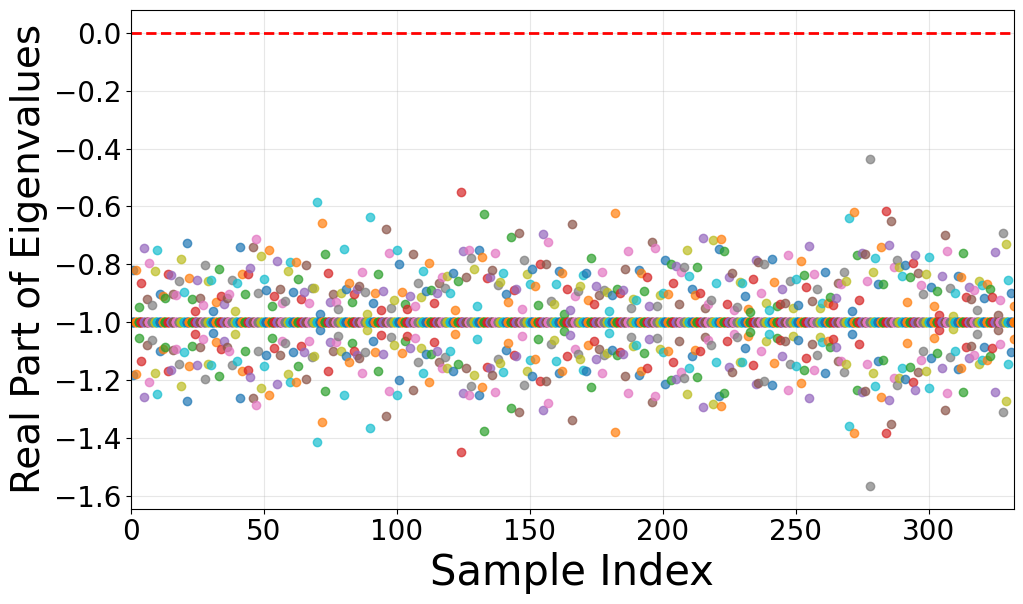


STABILITY SUMMARY

Stable samples: 332/332 (100.0%)


In [72]:
# visualise stability results
fig, ax1 = plt.subplots(1, 1, figsize=(10, 6))

# use actual number of samples
actual_no_samples = len(stability_results)
for i in range(actual_no_samples):
    real_parts = stability_results[i]['real_parts']
    ax1.plot([i+1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i+1}' if i < 5 else '')
ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
ax1.set_xlabel('Sample Index', fontsize=30)
ax1.set_ylabel('Real Part of Eigenvalues', fontsize=28)
actual_no_samples = len(stability_results)
ax1.set_xlim(0, actual_no_samples)
ax1.grid(True, alpha=0.3)

stable_count = sum(1 for r in stability_results if r['is_stable'])
unstable_count = actual_no_samples - stable_count

plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.savefig('Figures/stability.eps')
plt.show()

# print summary
print("\n" + "=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)
print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100*stable_count/actual_no_samples:.1f}%)")

In [13]:
# remove unstable theta
theta_opt = np.array(theta_opt)

# Identify unstable samples from stability_results
remove_row = [i for i, r in enumerate(stability_results) if not r['is_stable']]

max_index = theta_opt.shape[0] - 1
valid_remove_row = [i for i in remove_row if 0 <= i <= max_index]

for i in sorted(valid_remove_row, reverse=True):
    theta_opt = np.delete(theta_opt, i, axis=0)

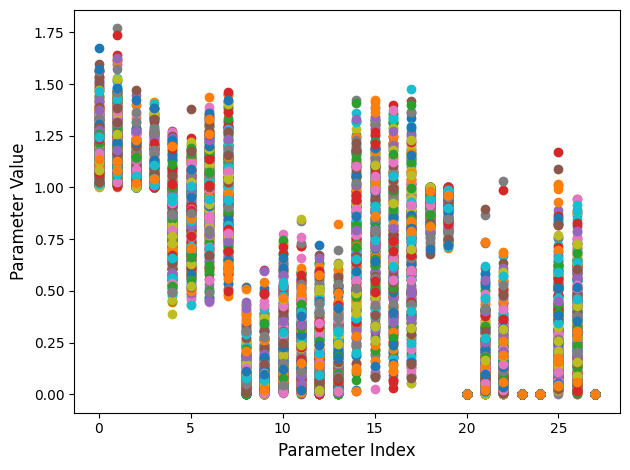

In [14]:
# raw values
for i in range(theta_opt.shape[0]):
    plt.plot(theta_opt[i, :], marker='o', linestyle=' ')
plt.xlabel('Parameter Index', fontsize=12)
plt.ylabel('Parameter Value', fontsize=12)
#plt.xlim(0,30)
plt.tight_layout()
plt.show()


# Compute Hessian

Processing 332 samples...
  Sample 1/332...
  Sample 101/332...
  Sample 201/332...
  Sample 301/332...
Completed processing 332 samples


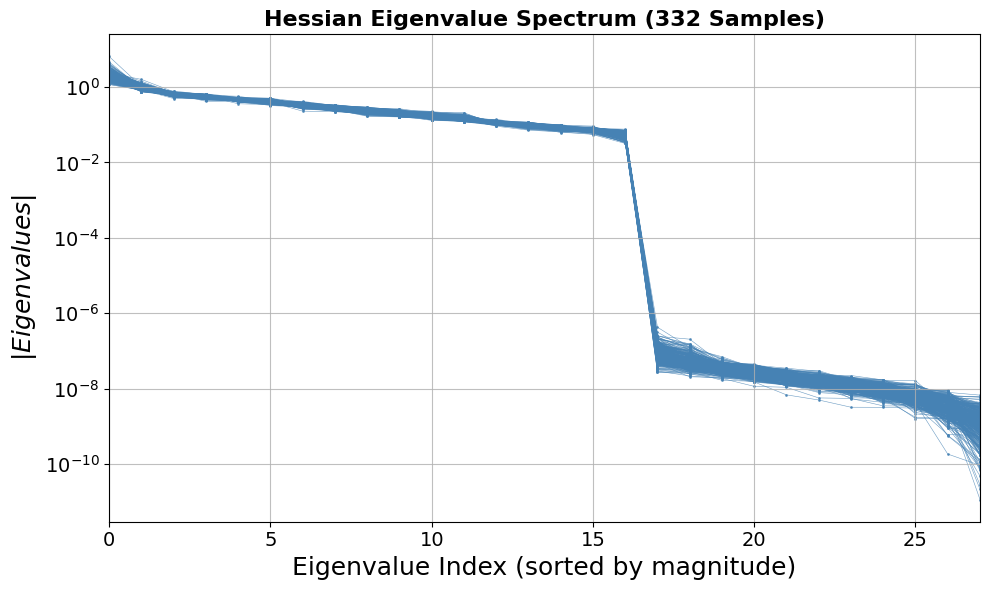

In [15]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [16]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)
    
    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)
    
    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)
    
    return eigenvectors_subspace2

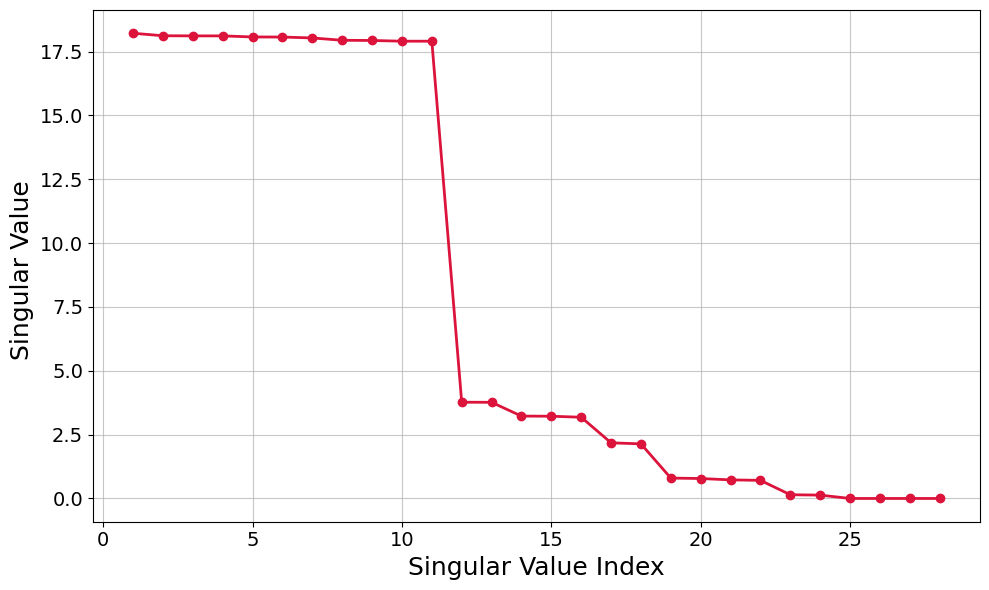

In [17]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(10, 6))
plt.plot(np.arange(1, len(S)+1), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=18)
plt.ylabel('Singular Value ', fontsize=18)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

In [88]:
def smoothed_sparse_rotation(U, iterations=1000, step_size=0.01, delta=0.01):
    n, k = U.shape
    Q = np.eye(k)
    
    for i in range(iterations):
        U_tilde = U @ Q
        
        # Smoothed L1 gradient (Huber-style)
        # Instead of np.sign, we use a gradient that scales down near zero
        grad = U.T @ (U_tilde / np.sqrt(U_tilde**2 + delta))
        
        # SVD Projection (the "Varimax Trick") for stability
        Z = Q - step_size * grad
        L, _, M_h = np.linalg.svd(Z)
        Q = L @ M_h
        print(np.sum(np.abs(U@Q)))
        
    return U @ Q, Q

In [89]:
Vt[:11].shape # orthonormal rows
Vt[:11].T.shape # orthonormal columns

(28, 11)

In [90]:
U_sparse, Q_matrix = smoothed_sparse_rotation(Vt[:11].T, iterations=1000)
print(np.sum(np.abs(U_sparse)))
with np.printoptions(precision=4, suppress=True):
    print(U_sparse)
    

25.488021083353253
25.40268276288358
25.317673911492566
25.23312771601976
25.149167244490524
25.065904617109364
24.98344024378879
24.901863065294386
24.82125051883693
24.74166814966938
24.66796678809621
24.597718375571795
24.52843739111313
24.46395758782335
24.401158251626217
24.33863642941213
24.276427902438243
24.214560373468416
24.153054525557348
24.091923825210532
24.031175483444795
23.97081076680437
23.910825589448585
23.85121176280807
23.79195756774555
23.733048577574355
23.6744685240134
23.616200052984837
23.558225711069976
23.50052865494814
23.44309351040493
23.385907102546703
23.328959174061985
23.272243042287656
23.215756223815333
23.15950094144528
23.10382824315473
23.050348401254247
22.997712916432153
22.94566213403854
22.896164235836984
22.85315611308371
22.81485329025837
22.776702694999337
22.738419297256478
22.700046007621985
22.661660747385596
22.623340083200894
22.585158430822492
22.547187475441024
22.509495724688705
22.472148342880196
22.4352071976338
22.3987310474914

In [91]:
U_sparse.shape

(28, 11)

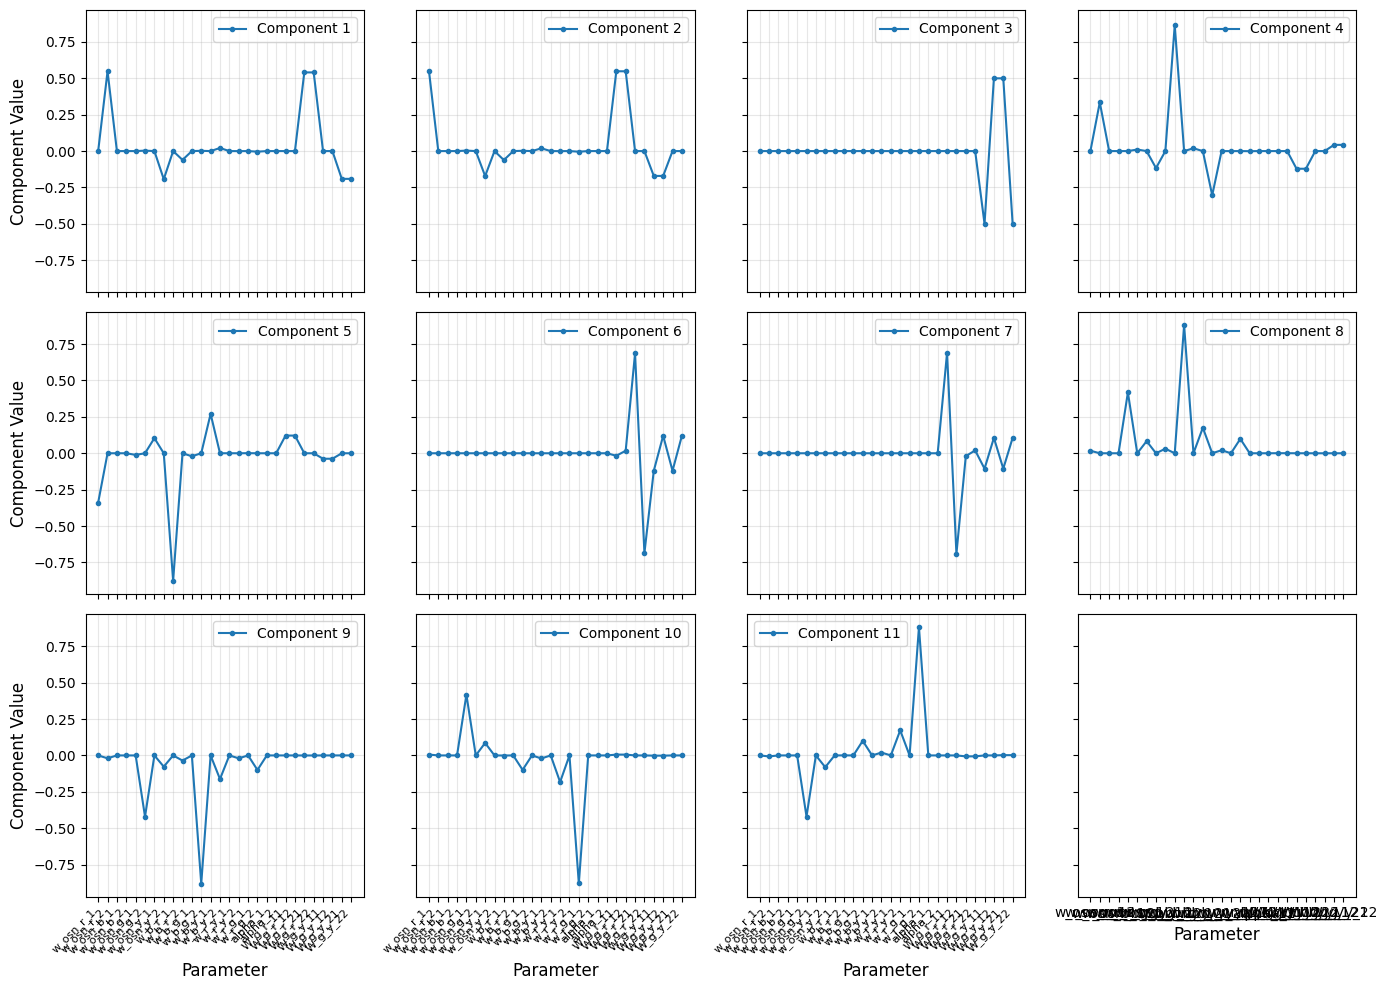

In [129]:
# Use U_sparse from smoothed sparse rotation (Cell 18)
# U_sparse has shape (total_vectors, n_params), matching U from SVD
# Take first 11 rows and transpose to get (n_params, 11) - matching Q = U[:11].T pattern
M = U_sparse  # Shape: (28 params, 11 components)


# Create parameter labels in the correct order
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

# Sort components by sparsity (sum of absolute values)
M_sums = np.abs(M).sum(0)
sorting_ind = np.argsort(M_sums)[::-1]
M_plot = M[:, sorting_ind]

# Plot all 11 components in subplots
fig, ax = plt.subplots(figsize=(14, 10), nrows=3, ncols=4, sharex=True, sharey=True)
for i in range(11):
    row, col = i // 4, i % 4
    ax[row, col].plot(M_plot[:, i], '.-', label=f'Component {i+1}')
    ax[row, col].set_xticks(range(len(param_labels)))
    ax[row, col].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=8)
    ax[row, col].grid(True, alpha=0.3)
    ax[row, col].legend(fontsize=10)
    
# Set labels for bottom row
for col in range(4):
    ax[2, col].set_xlabel('Parameter', fontsize=12)

# Set labels for left column
for row in range(3):
    ax[row, 0].set_ylabel('Component Value', fontsize=12)

plt.tight_layout()
plt.show()


# Varimax


In [85]:
def varimax(Q, gamma=1.0, q=20, tol=1e-6):
    """
    Orthogonal varimax rotation.

    Parameters
    ----------
    Q : array, shape (n, k)
        Matrix with orthonormal columns.
    gamma : float
        Varimax parameter. gamma=1.0 is standard varimax.
        gamma=0.0 gives quartimax.
    q : int
        Maximum number of iterations.
    tol : float
        Convergence tolerance.

    Returns
    -------
    M : array, shape (n, k)
        Rotated matrix (Q @ R).
    R : array, shape (k, k)
        Orthogonal rotation matrix.
    """
    n, k = Q.shape
    R = np.eye(k)
    d = 0

    for i in range(q):
        d_old = d

        # rotated loadings
        M = Q @ R

        # gradient-like update
        # diag term enforces column-wise normalization
        Lambda = M * (M**2 - gamma * np.mean(M**2, axis=0, keepdims=True))

        # SVD-based orthogonal update
        U, S, Vt = np.linalg.svd(Q.T @ Lambda)
        R = U @ Vt

        d = np.sum(S)
        if d_old != 0 and d / d_old < 1 + tol:
            break
        
        #print(np.sum(np.abs(Q@R)))
    return Q @ R, R


In [93]:
Q = U[:11].T
best_M, best_R = None, None
best_score = -np.inf

for _ in range(10):
    R0, _ = np.linalg.qr(np.random.randn(Q.shape[1], Q.shape[1]))
    M, R = varimax(Q @ R0)
    score = np.sum(np.abs(M))
    if score > best_score:
        best_score = score
        best_M, best_R = M, R @ R0
signs = np.sign(np.sum(best_M, axis=0))
best_M *= signs
best_R *= signs


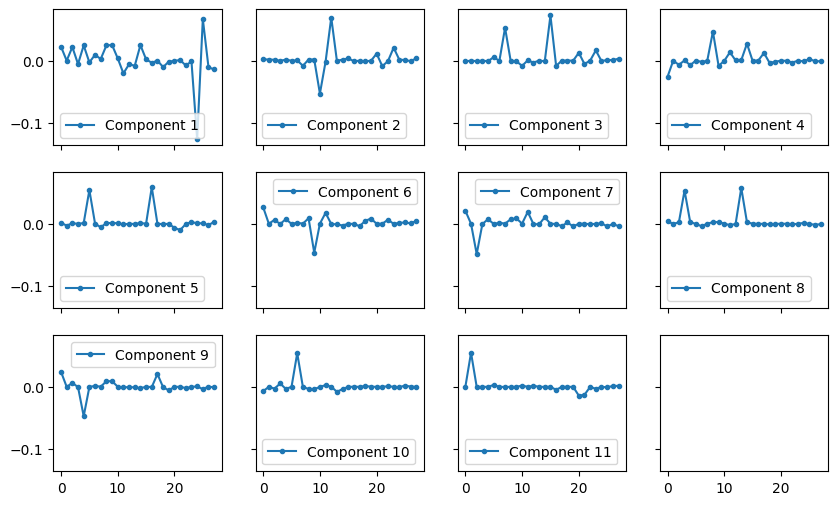

In [94]:
fig, ax = plt.subplots(figsize=(10, 6), nrows=3, ncols=4, sharex=True, sharey=True)
M_sums = np.abs(best_M).sum(0)
sorting_ind = np.argsort(M_sums)[::-1]
M_plott = best_M[:, sorting_ind]
for i in range(11):
    ax[i//4, i%4].plot(M_plott[:, i], '.-', label=f'Component {i+1}')
    ax[i//4, i%4].legend()
# plt.tight_layout()
plt.show()


# Step in delta theta

Delta_theta 0, Epsilon 0, Sample 0
Delta_theta 0, Epsilon 0, Sample 1
Delta_theta 0, Epsilon 1, Sample 0
Delta_theta 0, Epsilon 1, Sample 1
Delta_theta 0, Epsilon 2, Sample 0
Delta_theta 0, Epsilon 2, Sample 1
Delta_theta 0, Epsilon 3, Sample 0
Delta_theta 0, Epsilon 3, Sample 1
Delta_theta 0, Epsilon 4, Sample 0
Delta_theta 0, Epsilon 4, Sample 1
Delta_theta 0, Epsilon 5, Sample 0
Delta_theta 0, Epsilon 5, Sample 1
Delta_theta 0, Epsilon 6, Sample 0
Delta_theta 0, Epsilon 6, Sample 1
Delta_theta 0, Epsilon 7, Sample 0
Delta_theta 0, Epsilon 7, Sample 1
Delta_theta 0, Epsilon 8, Sample 0
Delta_theta 0, Epsilon 8, Sample 1
Delta_theta 0, Epsilon 9, Sample 0
Delta_theta 0, Epsilon 9, Sample 1
Delta_theta 0, Epsilon 10, Sample 0
Delta_theta 0, Epsilon 10, Sample 1
Delta_theta 0, Epsilon 11, Sample 0
Delta_theta 0, Epsilon 11, Sample 1
Delta_theta 0, Epsilon 12, Sample 0
Delta_theta 0, Epsilon 12, Sample 1
Delta_theta 0, Epsilon 13, Sample 0
Delta_theta 0, Epsilon 13, Sample 1
Delta_theta 

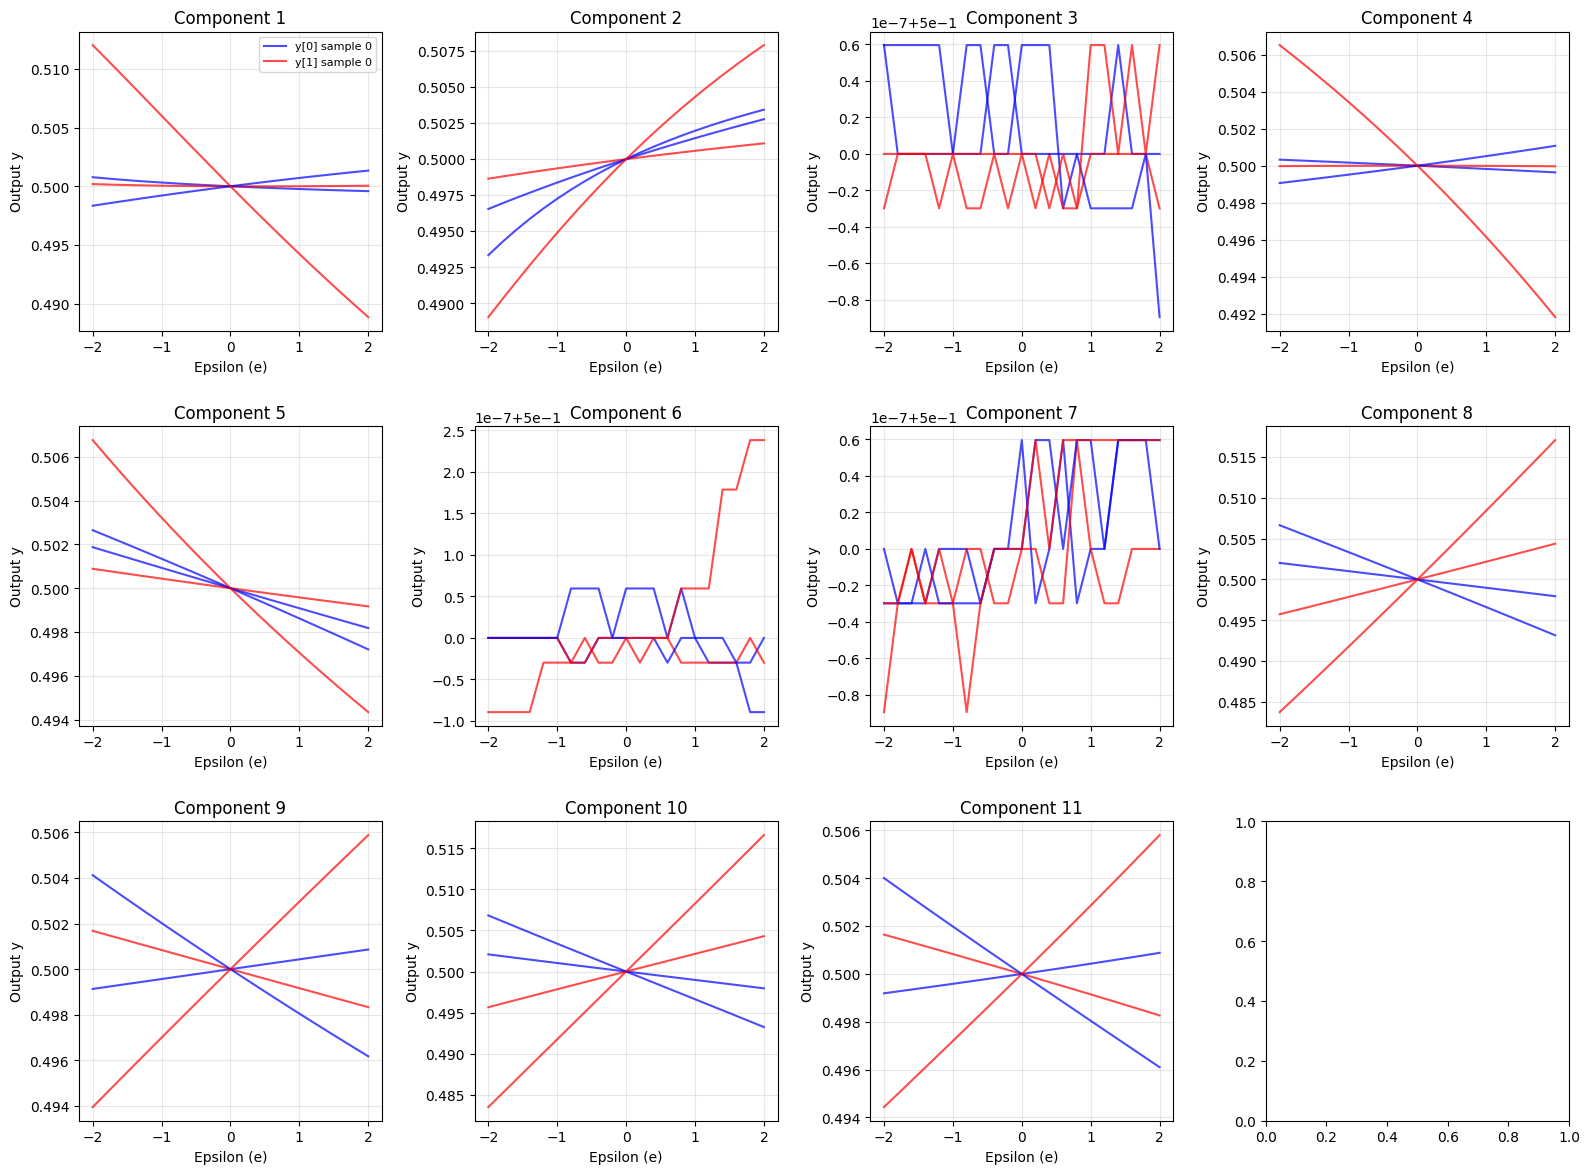

In [136]:
e = np.arange(-2, 2+0.2, 0.2)
n_samples = 2  # Number of samples to process

# Create figure with 3x4 subplots
fig, ax = plt.subplots(3, 4, figsize=(16, 12))
ax = ax.flatten()  # Flatten to 1D array for easier indexing

for k in range(11):  #11 delta thetas
    y_save = []  # Reset for each component
    
    for i in range(len(e)):
        theta_step = theta_opt + e[i] * M_plot[:, k]
        theta_step = theta_step[:n_samples]  # Pick first n_samples rows

        y_samples = []
        for j in range(theta_step.shape[0]):
            r, g, b, y = mitral_output(theta_step[j], x, m, n_r, n_b, n_g, n_y)
            y_samples.append(y)
            print(f"Delta_theta {k}, Epsilon {i}, Sample {j}")
        
        y_save.append(np.array(y_samples))  # Shape: (n_samples, m)
    
    # Convert to array: Shape: (len(e), n_samples, m)
    y_array = np.array(y_save)
    
    # Plot in subplot k
    for sample_idx in range(n_samples):
        ax[k].plot(e, y_array[:, sample_idx, 0], color='blue', alpha=0.7, label=f'y[0] sample {sample_idx}' if sample_idx == 0 else '')
        ax[k].plot(e, y_array[:, sample_idx, 1], color='red', alpha=0.7, label=f'y[1] sample {sample_idx}' if sample_idx == 0 else '')
    
    ax[k].set_xlabel('Epsilon (e)')
    ax[k].set_ylabel('Output y')
    ax[k].set_title(f'Component {k+1}')
    ax[k].grid(True, alpha=0.3)
    if k == 0:  # Add legend only to first subplot
        ax[k].legend(fontsize=8)

plt.tight_layout()
plt.show()


# Zoom ins


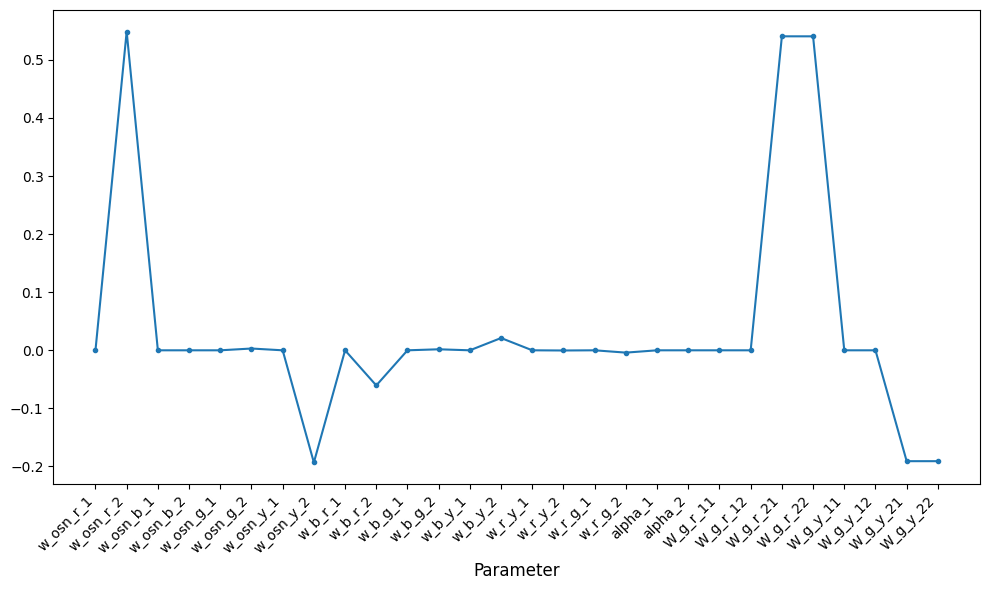

In [95]:

plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 0], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

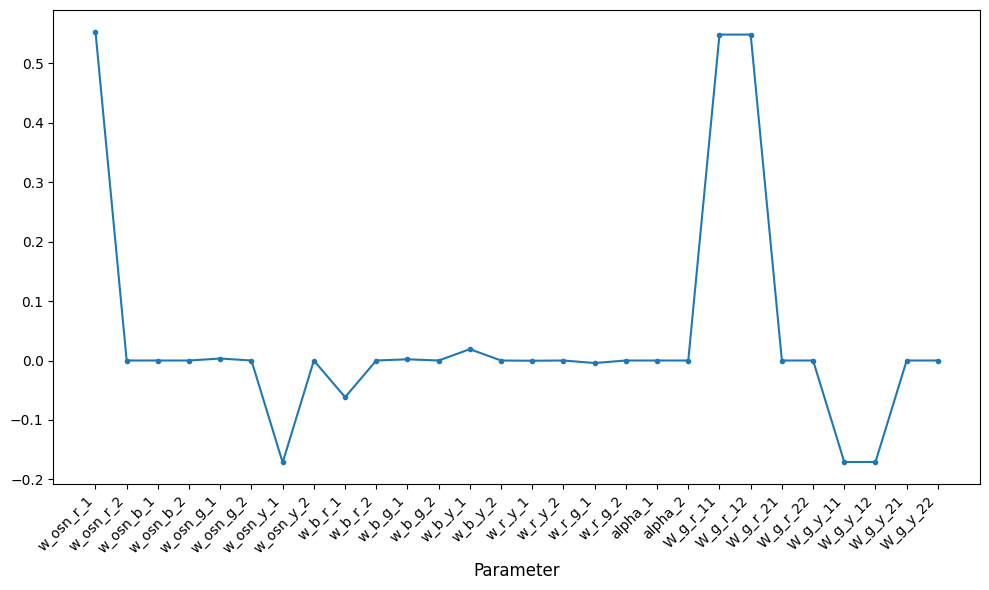

In [131]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 1], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

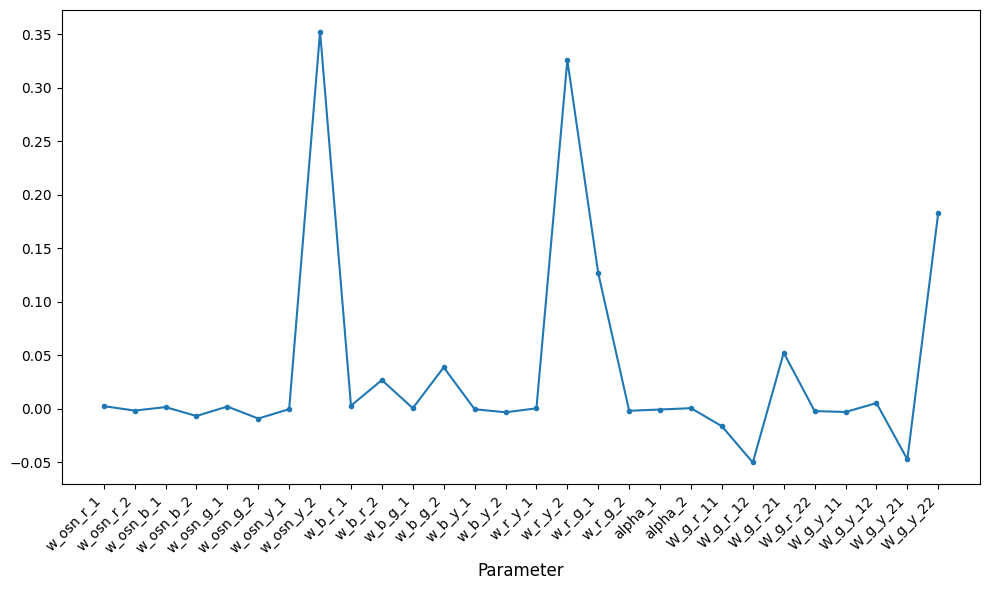

In [83]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 2], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

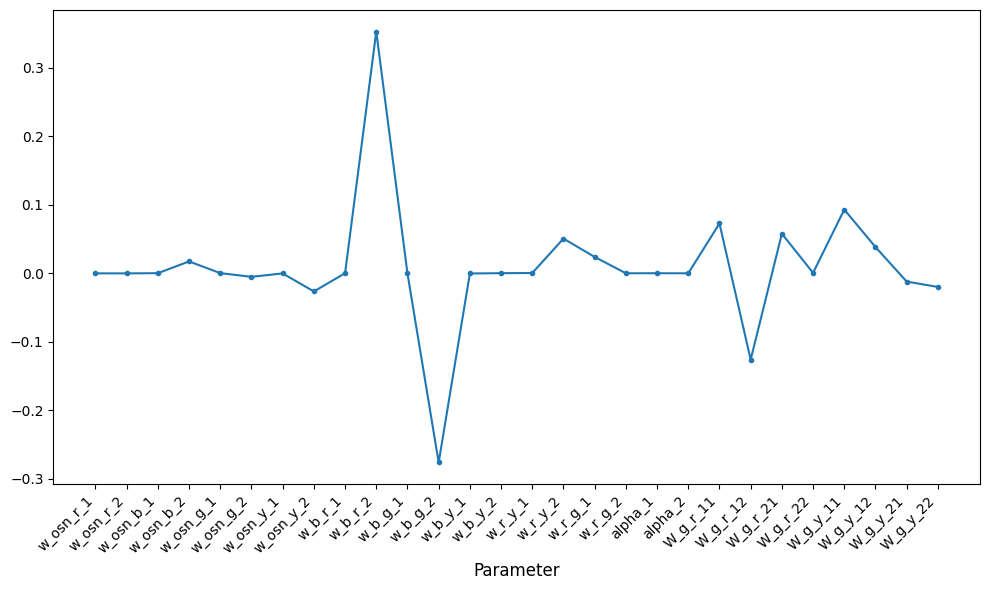

In [84]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 3], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

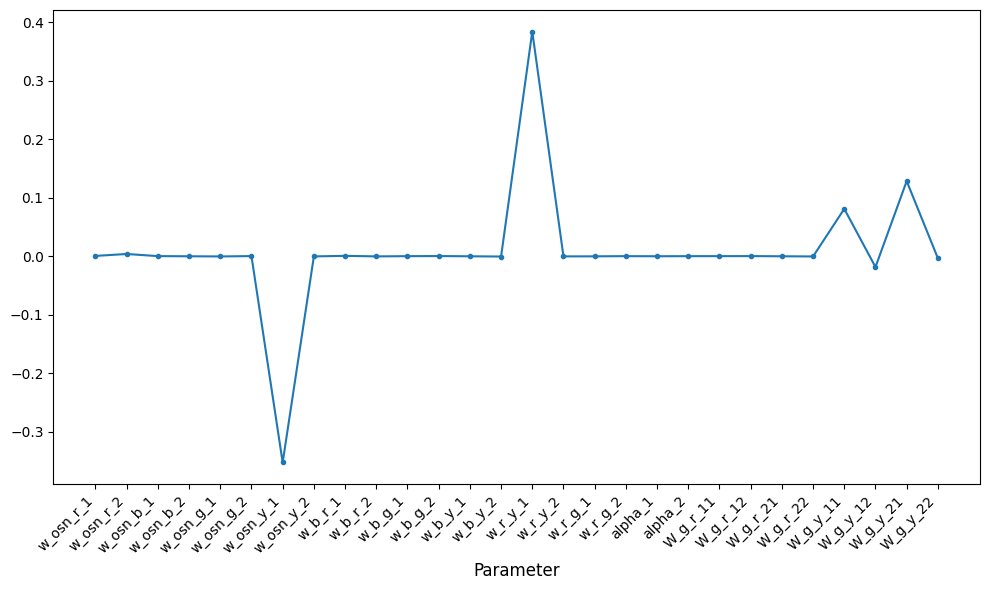

In [85]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 4], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

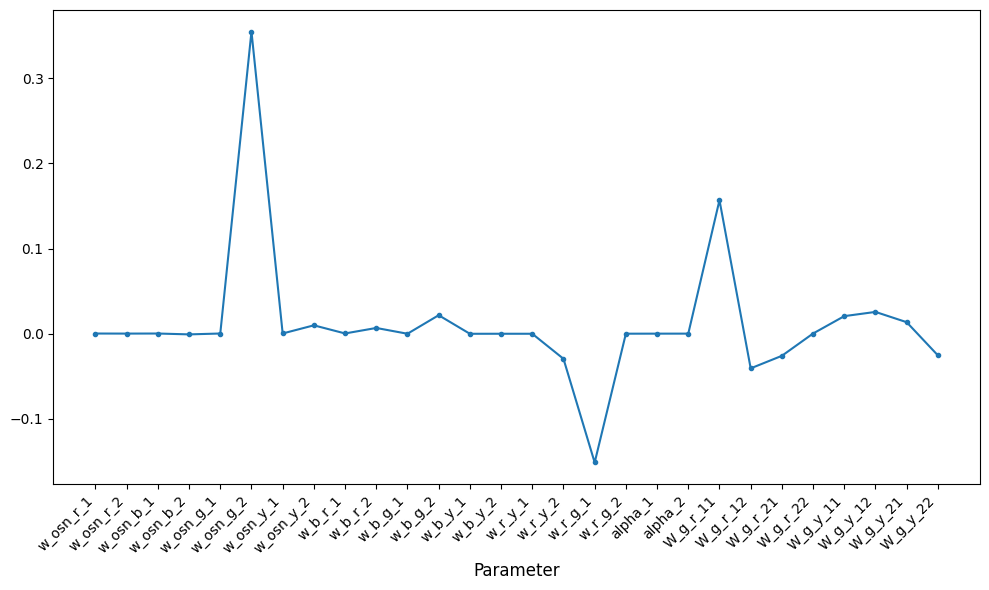

In [86]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 5], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

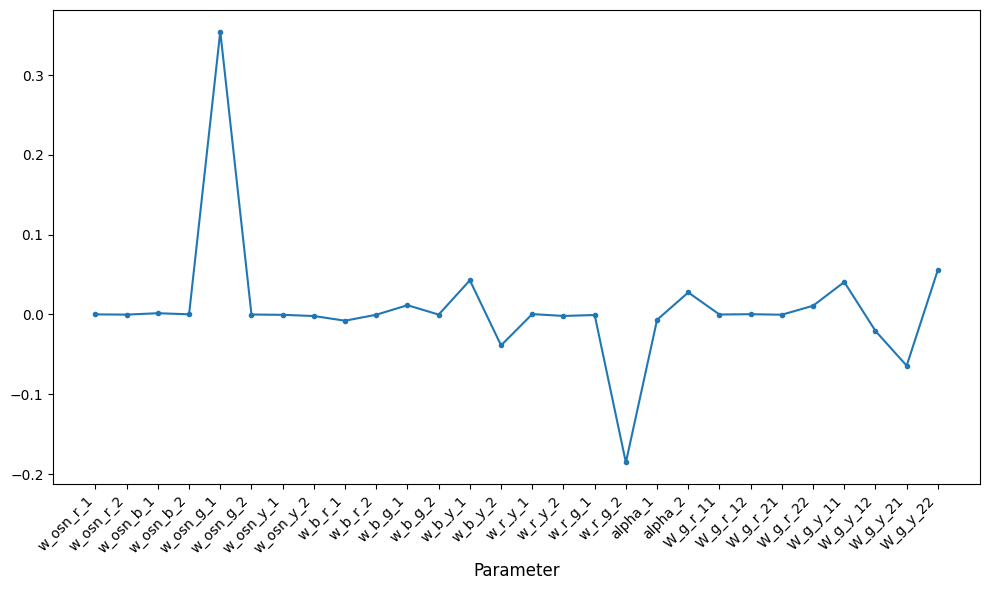

In [88]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 6], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

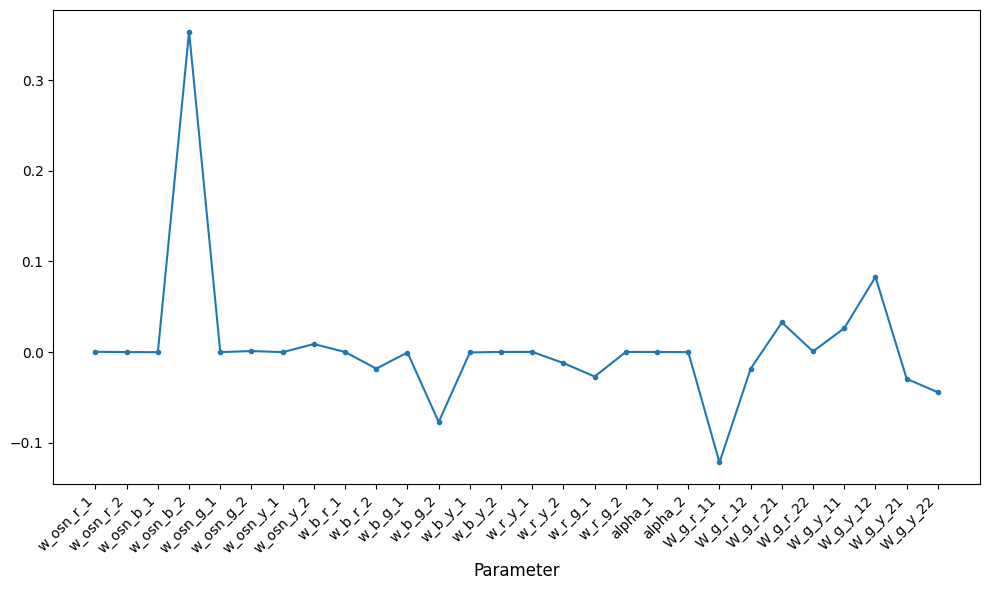

In [89]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 7], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

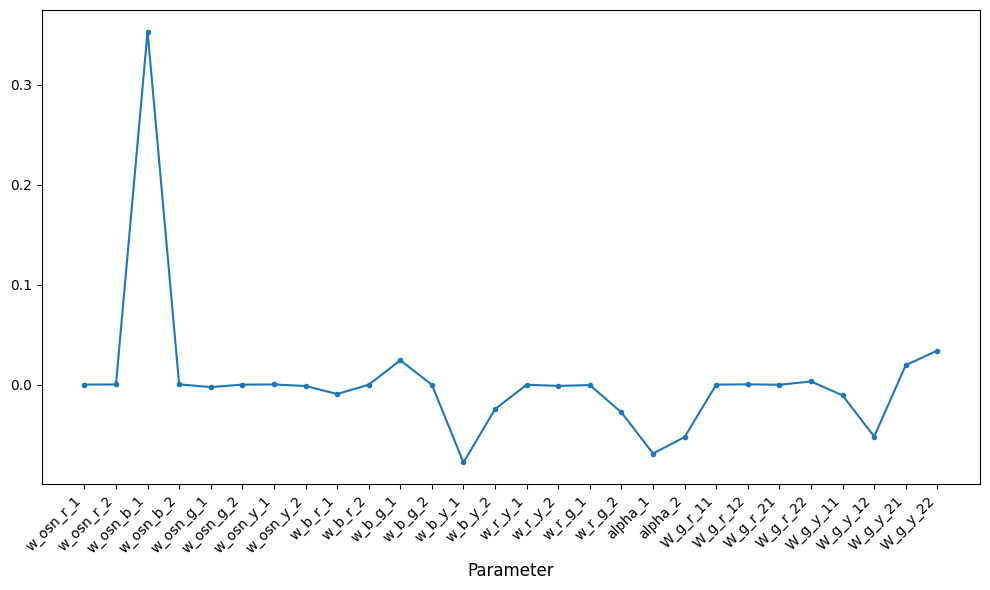

In [90]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 8], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

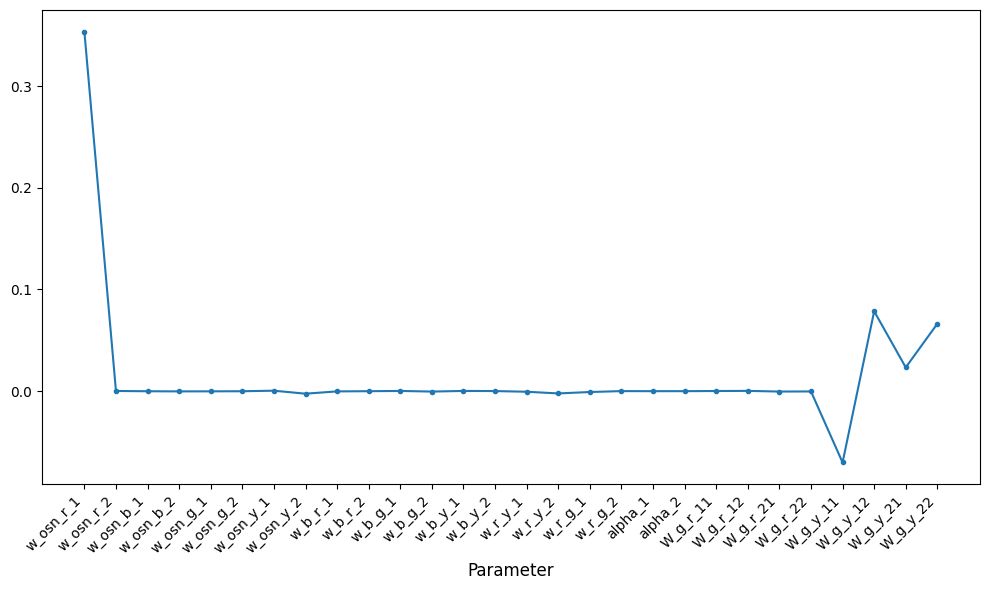

In [91]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 9], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

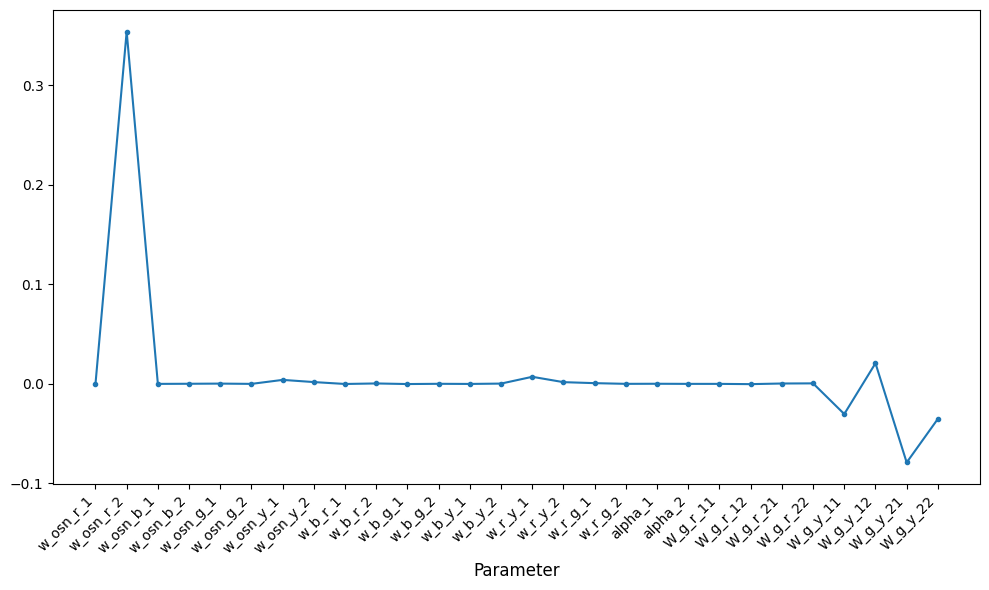

In [82]:
plt.figure(figsize=(10, 6))
plt.plot(M_plot[:, 10], '.-')

# Create x-axis labels in the specified order (m=2, so each weight has 2 elements)
# Order: w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y
param_labels = [
    'w_osn_r_1', 'w_osn_r_2',
    'w_osn_b_1', 'w_osn_b_2',
    'w_osn_g_1', 'w_osn_g_2',
    'w_osn_y_1', 'w_osn_y_2',
    'w_b_r_1', 'w_b_r_2',
    'w_b_g_1', 'w_b_g_2',
    'w_b_y_1', 'w_b_y_2',
    'w_r_y_1', 'w_r_y_2',
    'w_r_g_1', 'w_r_g_2',
    'alpha_1', 'alpha_2',
    'W_g_r_11', 'W_g_r_12', 'W_g_r_21', 'W_g_r_22',
    'W_g_y_11', 'W_g_y_12', 'W_g_y_21', 'W_g_y_22'
]

plt.xticks(range(len(param_labels)), param_labels, rotation=45, ha='right')
plt.xlabel('Parameter', fontsize=12)
plt.tight_layout()
plt.show()

# Visualise

In [142]:
import plotly.graph_objects as go
import plotly.express as px

def visualize_network(theta, m, sample_idx=0, top_n_connections=None):
    """
    Visualize the trained network connectivity using plotly.
    
    Parameters:
    -----------
    theta : array-like
        Parameter vector or matrix (if multiple samples, use sample_idx)
    m : int
        Number of mitral neurons (glomeruli)
    sample_idx : int, optional
        If theta is a matrix, which sample to visualize (default: 0)
    top_n_connections : int, optional
        Show only top N connections by weight (default: None, shows all)
    """
    # Handle multiple samples
    theta = np.array(theta)
    if len(theta.shape) > 1:
        theta = theta[sample_idx]
    
    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    
    # Convert JAX arrays to numpy for plotting
    w_osn_r = np.array(w_osn_r)
    w_osn_b = np.array(w_osn_b)
    w_osn_g = np.array(w_osn_g)
    w_osn_y = np.array(w_osn_y)
    w_b_r = np.array(w_b_r)
    w_b_g = np.array(w_b_g)
    w_b_y = np.array(w_b_y)
    w_r_y = np.array(w_r_y)
    w_r_g = np.array(w_r_g)
    W_g_r = np.array(W_g_r)
    W_g_y = np.array(W_g_y)
    
    # Create node positions
    # Layout: OSN at top, then r, g, b, y neurons in rows
    node_positions = {}
    node_labels = []
    node_types = []
    
    # OSN nodes (OSN0 and OSN1)
    for j in range(m):
        node_id = f'OSN{j}'
        x_pos = (j - (m-1)/2) * 1.5
        node_positions[node_id] = (x_pos, 2)
        node_labels.append(f'OSN{j}')
        node_types.append('OSN')
    
    # Neuron nodes
    neuron_types = ['r', 'g', 'b', 'y']
    y_positions = [1.5, 1.0, 0.5, 0]
    
    for i, (neuron_type, y_pos) in enumerate(zip(neuron_types, y_positions)):
        for j in range(m):
            node_id = f'{neuron_type}{j}'
            x_pos = (j - (m-1)/2) * 1.5
            node_positions[node_id] = (x_pos, y_pos)
            node_labels.append(f'{neuron_type.upper()}{j}')
            node_types.append(neuron_type)
    
    # Collect all connections with their weights
    connections = []
    
    # OSN0 -> G0, Y0, R0, B0 (excitatory - positive weights)
    # OSN1 -> G1, Y1, R1, B1 (excitatory - positive weights)
    for j in range(m):
        connections.append((f'OSN{j}', f'r{j}', float(w_osn_r[j]), f'OSN{j}->R{j}'))
        connections.append((f'OSN{j}', f'b{j}', float(w_osn_b[j]), f'OSN{j}->B{j}'))
        connections.append((f'OSN{j}', f'g{j}', float(w_osn_g[j]), f'OSN{j}->G{j}'))
        connections.append((f'OSN{j}', f'y{j}', float(w_osn_y[j]), f'OSN{j}->Y{j}'))
    
    # B0 -> G0, R0, Y0 (inhibitory - negative weights)
    # B1 -> G1, R1, Y1 (inhibitory - negative weights)
    for j in range(m):
        # B inhibits R, G, Y (use negative weights)
        connections.append((f'b{j}', f'r{j}', -float(w_b_r[j]), f'B{j}->R{j}'))
        connections.append((f'b{j}', f'g{j}', -float(w_b_g[j]), f'B{j}->G{j}'))
        connections.append((f'b{j}', f'y{j}', -float(w_b_y[j]), f'B{j}->Y{j}'))
    
    # R0 -> G0, Y0 (excitatory - positive weights)
    # R1 -> G1, Y1 (excitatory - positive weights)
    for j in range(m):
        connections.append((f'r{j}', f'g{j}', float(w_r_g[j]), f'R{j}->G{j}'))
        connections.append((f'r{j}', f'y{j}', float(w_r_y[j]), f'R{j}->Y{j}'))
    
    # G0 -> R1, Y1 (inhibitory - negative weights, cross connections)
    # G1 -> R0, Y0 (inhibitory - negative weights, cross connections)
    for i in range(m):
        for j in range(m):
            if i != j:  # Cross connections only (G0->R1, G1->R0, etc.)
                connections.append((f'g{i}', f'r{j}', -float(W_g_r[i, j]), f'G{i}->R{j}'))
                connections.append((f'g{i}', f'y{j}', -float(W_g_y[i, j]), f'G{i}->Y{j}'))
    
    # Y0 -> ? (Y inhibits, but need to check what Y inhibits)
    # Based on the model, Y is output, but if Y has inhibitory connections, add them here
    # For now, Y doesn't have outgoing connections in the standard model
    
    # Filter to top N connections if specified
    if top_n_connections is not None:
        connections.sort(key=lambda x: abs(x[2]), reverse=True)
        connections = connections[:top_n_connections]
    
    # Extract edge data with actual weights (not absolute) to determine inhibitory vs excitatory
    edge_data = []
    
    for source, target, weight, label in connections:
        x0, y0 = node_positions[source]
        x1, y1 = node_positions[target]
        edge_data.append({
            'source': source,
            'target': target,
            'x0': x0,
            'y0': y0,
            'x1': x1,
            'y1': y1,
            'weight': weight,
            'abs_weight': abs(weight),
            'label': label,
            'is_excitatory': weight > 0,
            'is_inhibitory': weight < 0
        })
    
    # Normalize edge weights for visualization (based on absolute values)
    abs_weights = [e['abs_weight'] for e in edge_data]
    if abs_weights:
        max_weight = max(abs_weights)
        min_weight = min(abs_weights)
        if max_weight > min_weight:
            for e in edge_data:
                e['width'] = 2 + 8 * (e['abs_weight'] - min_weight) / (max_weight - min_weight)
        else:
            for e in edge_data:
                e['width'] = 5
    else:
        for e in edge_data:
            e['width'] = 5
    
    # Create edge traces with color coding for inhibitory vs excitatory
    # Note: Green cells inhibit (red lines), Red cells excite (green lines)
    edge_traces = []
    arrow_annotations = []
    
    for e in edge_data:
        # Determine if connection is from a Green cell (inhibitory) or Red cell (excitatory)
        source_type = e['source'][0].lower() if len(e['source']) > 0 else ''
        is_from_green = source_type == 'g'
        is_from_red = source_type == 'r'
        
        # Color based on source cell type:
        # Green cells inhibit -> Red lines
        # Red cells excite -> Green lines
        # Other excitatory (OSN) -> Green lines
        # Other inhibitory (B) -> Red lines
        if is_from_green or (e['is_inhibitory'] and not is_from_red):
            # Inhibitory: Red shades (from Green cells or Blue cells)
            if e['abs_weight'] > 0.5:
                color = 'rgba(200, 0, 0, 0.8)'  # Dark red for strong inhibitory
            elif e['abs_weight'] > 0.1:
                color = 'rgba(255, 0, 0, 0.6)'  # Bright red for medium inhibitory
            else:
                color = 'rgba(255, 182, 193, 0.4)'  # Light red/pink for weak inhibitory
        else:  # excitatory (from Red cells or OSN)
            # Excitatory: Green shades (from Red cells or OSN)
            if e['abs_weight'] > 0.5:
                color = 'rgba(0, 200, 0, 0.8)'  # Dark green for strong excitatory
            elif e['abs_weight'] > 0.1:
                color = 'rgba(0, 255, 0, 0.6)'  # Bright green for medium excitatory
            else:
                color = 'rgba(144, 238, 144, 0.4)'  # Light green for weak excitatory
        
        # Calculate curved path to avoid overlap
        # Use a quadratic Bezier curve with a control point offset perpendicular to the line
        dx = e['x1'] - e['x0']
        dy = e['y1'] - e['y0']
        length = np.sqrt(dx**2 + dy**2)
        
        # Create curved path with multiple points for smooth curve
        n_points = 20
        curve_strength = 0.3  # How much the curve bends (adjust for more/less curvature)
        
        # Perpendicular offset for curve
        perp_x = -dy / length if length > 0 else 0
        perp_y = dx / length if length > 0 else 0
        
        # Vary curve direction to avoid overlap between parallel connections
        # Use a hash of source and target to determine curve direction
        connection_hash = hash((e['source'], e['target'])) % 2
        curve_direction = 1 if connection_hash == 0 else -1
        
        # Control point at midpoint with perpendicular offset
        mid_x = (e['x0'] + e['x1']) / 2
        mid_y = (e['y0'] + e['y1']) / 2
        control_x = mid_x + perp_x * curve_strength * length * curve_direction
        control_y = mid_y + perp_y * curve_strength * length * curve_direction
        
        # Generate points along quadratic Bezier curve
        curve_x = []
        curve_y = []
        for i in range(n_points + 1):
            t = i / n_points
            # Quadratic Bezier: (1-t)^2*P0 + 2*(1-t)*t*P1 + t^2*P2
            x = (1-t)**2 * e['x0'] + 2*(1-t)*t * control_x + t**2 * e['x1']
            y = (1-t)**2 * e['y0'] + 2*(1-t)*t * control_y + t**2 * e['y1']
            curve_x.append(x)
            curve_y.append(y)
        
        # Create curved line trace
        edge_traces.append(
            go.Scatter(
                x=curve_x,
                y=curve_y,
                mode='lines',
                line=dict(width=e['width'], color=color, shape='spline', smoothing=1.0),
                hoverinfo='skip',
                showlegend=False
            )
        )
        
        # Calculate arrow position along the curved path (near target)
        # Use the last few points of the curve to determine arrow direction
        if len(curve_x) >= 3:
            # Arrow endpoint: near the end of the curve (but not at the node)
            node_radius = 0.15
            arrow_end_idx = len(curve_x) - 2  # Second to last point
            arrow_start_idx = max(0, len(curve_x) - 5)  # A few points before end
            
            arrow_end_x = curve_x[arrow_end_idx]
            arrow_end_y = curve_y[arrow_end_idx]
            arrow_start_x = curve_x[arrow_start_idx]
            arrow_start_y = curve_y[arrow_start_idx]
            
            # Add arrow annotation (arrow goes from ax,ay to x,y)
            arrow_annotations.append(
                dict(
                    x=arrow_end_x,  # Arrow endpoint (near target along curve)
                    y=arrow_end_y,
                    ax=arrow_start_x,  # Arrow start point (along curve)
                    ay=arrow_start_y,
                    xref='x',
                    yref='y',
                    axref='x',
                    ayref='y',
                    showarrow=True,
                    arrowhead=2,
                    arrowsize=1.5,
                    arrowwidth=max(1, e['width'] * 0.4),
                    arrowcolor=color,
                    standoff=2,
                    startstandoff=2
                )
            )
    
    # Create node trace
    node_x = [pos[0] for pos in node_positions.values()]
    node_y = [pos[1] for pos in node_positions.values()]
    
    # Color nodes by type
    node_colors = []
    color_map = {'OSN': 'purple', 'r': 'red', 'g': 'green', 'b': 'blue', 'y': 'yellow'}
    for node_type in node_types:
        node_colors.append(color_map.get(node_type, 'gray'))
    
    node_trace = go.Scatter(
        x=node_x,
        y=node_y,
        mode='markers+text',
        marker=dict(
            size=30,
            color=node_colors,
            line=dict(width=2, color='black')
        ),
        text=node_labels,
        textposition="middle center",
        textfont=dict(size=10, color='white', family='Arial Black'),
        hoverinfo='text',
        showlegend=False
    )
    
    # Create figure
    fig = go.Figure()
    
    # Add edges
    for trace in edge_traces:
        fig.add_trace(trace)
    
    # Add nodes
    fig.add_trace(node_trace)
    
    # Count excitatory vs inhibitory connections
    n_excitatory = sum(1 for e in edge_data if e['is_excitatory'])
    n_inhibitory = sum(1 for e in edge_data if e['is_inhibitory'])
    
    # Update layout with arrow annotations
    fig.update_layout(
        title=dict(
            text=f'Network Connectivity Visualization (Sample {sample_idx+1})<br>' +
                 '<span style="font-size:14px; color:green">Green = Excitatory (R cells)</span> | ' +
                 '<span style="font-size:14px; color:red">Red = Inhibitory (G, B cells)</span>',
            x=0.5,
            font=dict(size=20)
        ),
        showlegend=False,
        hovermode='closest',
        margin=dict(b=20, l=5, r=5, t=60),
        annotations=arrow_annotations + [
            dict(
                text=f"Showing {len(connections)} connections<br>" +
                     f"Excitatory: {n_excitatory} | Inhibitory: {n_inhibitory}<br>" +
                     (f"Strongest: {max(abs_weights):.4f}, Weakest: {min(abs_weights):.4f}" 
                      if abs_weights else "No connections"),
                showarrow=False,
                xref="paper", yref="paper",
                x=0.005, y=-0.002,
                xanchor="left", yanchor="bottom",
                font=dict(size=12)
            )
        ],
        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        plot_bgcolor='white',
        width=1000,
        height=800
    )
    
    return fig



In [143]:
# Visualize the network for the first optimized sample
# You can change sample_idx to visualize different samples
fig = visualize_network(M_plot[:, 10], m, sample_idx=0, top_n_connections=None) 
fig.show()

# colour scheme
# red: strong inhibition
# orange: strong excitation
# blue: weak inhibition
# green: weak excitation
